# Open-Domain Question Answering: From Keyword Search to Transformer Retrievers

This project builds and benchmarks the **retrieval stage of a question-answering / RAG system** on real Google search questions, then adds a transformer **reader** that extracts the final answer, which makes it a complete *retriever → reader* QA pipeline.

**Dataset:** [BEIR Natural Questions](https://github.com/beir-cellar/beir): real Google queries with relevant Wikipedia passages. All 3,452 test questions are used, searched over a corpus of their relevant passages **plus ~100k random distractor passages** from the 2.68M-passage collection, so each retriever has to find the answer among mostly unrelated text.

**Retrievers compared** (three generations of text representation):

| Era | Method | Representation |
|---|---|---|
| Keywords | BM25 | Sparse term matching (TF-IDF style) |
| Static embeddings | Word2Vec (trained on the corpus, tuned) | Averaged word vectors |
| Transformers (2021) | MiniLM-L6, MPNet-base | Contextual sentence embeddings |
| Transformers (2023) | BGE-small v1.5 | Retrieval-tuned contrastive embeddings |
| Transformers (2025) | Qwen3-Embedding-0.6B, EmbeddingGemma-300M | LLM-based embedding models |
| Hybrid | BM25 + best transformer | Reciprocal Rank Fusion of keyword and dense rankings |

**Evaluation:** Recall@k, Precision@5 and MRR for retrieval. For end-to-end QA, the best retriever (selected automatically by MRR) feeds its top-5 passages to `deepset/roberta-base-squad2`, an extractive reader.

```
Question ──► Retriever (top-k passages) ──► Reader (answer span) ──► Answer + source passage
```

## Setup and Configuration

In [1]:
import os
import glob

# Runs both locally and on Kaggle. On Kaggle, attach two datasets:
#   1. the BEIR NQ data (folder containing corpus.jsonl, queries.jsonl, qrels/)
#   2. this project's src/ folder
IS_KAGGLE = os.path.exists("/kaggle/input")

if IS_KAGGLE:
    SRC_DIR = os.path.dirname(glob.glob("/kaggle/input/**/data_loader.py", recursive=True)[0])
    DATA_DIR = os.path.dirname(glob.glob("/kaggle/input/**/nq/corpus.jsonl", recursive=True)[0])
    OUTPUT_DIR = "/kaggle/working"
    # EmbeddingGemma is a gated model: attach an HF_TOKEN secret (Add-ons → Secrets) to include it
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print(f"⚠️  HF_TOKEN secret not available: {e}")
else:
    SRC_DIR = "../src"
    DATA_DIR = None  # defaults to ../dataset/nq (downloaded if missing)
    OUTPUT_DIR = "../results"

QUERY_SAMPLE_SIZE = None      # None = all 3,452 NQ test questions
NUM_DISTRACTORS = 100_000     # random non-relevant passages added to the corpus
W2V_TUNING_TRIALS = 4         # random Word2Vec configurations to try
QA_EVAL_QUERIES = 500         # questions used for end-to-end QA evaluation
TOP_K = 20
SEED = 42

# Gated models need an HF token with access. When True, the notebook stops in the
# setup cell if access is missing, instead of skipping the model after hours of work.
GATED_MODELS = ["google/embeddinggemma-300m"]
REQUIRE_GATED_MODELS = IS_KAGGLE

print(f"Environment: {'Kaggle' if IS_KAGGLE else 'local'}")
print(f"src: {SRC_DIR}")
print(f"data: {DATA_DIR or '../dataset/nq'}")

Environment: Kaggle
src: /kaggle/input/datasets/custardapple47/srcdat
data: /kaggle/input/datasets/custardapple47/beirnq/nq


In [2]:
if IS_KAGGLE:
    %pip install -q rank-bm25 gensim "sentence-transformers>=5.0" "transformers>=4.56"

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
import gc
import json
import time
import random
import logging
import warnings

import numpy as np
import torch
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
for name in ["httpx", "sentence_transformers", "transformers", "huggingface_hub", "gensim", "data_loader"]:
    logging.getLogger(name).setLevel(logging.WARNING)

sys.path.insert(0, SRC_DIR)
from data_loader import DataLoader
from bm25_retriever import BM25Retriever
from word2vec_retriever import Word2VecRetriever
from transformer_retriever import TransformerRetriever
from qa_reader import ExtractiveReader
from evaluator import IRMetrics
from utils import (create_comparison_visualization, print_comparison_table,
                   random_param_combinations, compare_retrieval_methods)

from hybrid_retriever import HybridRetriever
from huggingface_hub import whoami, hf_hub_download

# Fail fast if a gated model can't be downloaded (checked before any long-running work)
hf_token = os.environ.get("HF_TOKEN")
try:
    print(f"🔑 HF token: {whoami(token=hf_token)['name'] if hf_token else 'not set'}")
except Exception as e:
    print(f"⚠️  HF token is invalid: {e}")
for repo in GATED_MODELS:
    try:
        hf_hub_download(repo, "config.json", token=hf_token)
        print(f"✅ Access to gated model {repo}")
    except Exception as e:
        if REQUIRE_GATED_MODELS:
            raise RuntimeError(f"No access to gated model {repo}. Attach an HF_TOKEN secret for an account that "
                               f"accepted the model license, or set REQUIRE_GATED_MODELS = False.\n{e}") from e
        print(f"⚠️  No access to gated model {repo}; it will be skipped")

# Every method registers here so the best one can be picked automatically
retrievers, all_results, all_metrics = {}, {}, {}

print(f"✅ Libraries loaded | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

🔑 HF token: beetroot67


config.json:   0%|          | 0.00/1.49k [00:00<?, ?B/s]

✅ Access to gated model google/embeddinggemma-300m
✅ Libraries loaded | GPU: Tesla T4


## Load Natural Questions

Every relevant passage for the selected questions is kept, then `NUM_DISTRACTORS` random passages are mixed in. Without distractors, every passage in the corpus would be the answer to *some* question, which makes retrieval artificially easy.

In [4]:
loader = DataLoader("BeIR/nq", data_dir=DATA_DIR)
loader.load_dataset(split="test", query_sample_size=QUERY_SAMPLE_SIZE,
                    num_distractors=NUM_DISTRACTORS, random_seed=SEED)
corpus_texts, query_texts, qrels_dict = loader.prepare_retrieval_data()

num_relevant = len({d for rels in qrels_dict.values() for d in rels})
print(f"✅ Dataset loaded")
print(f"  ❓ Questions: {len(query_texts):,}")
print(f"  📄 Passages:  {len(corpus_texts):,} ({num_relevant:,} relevant + {len(corpus_texts) - num_relevant:,} distractors)")

print(f"\n💡 Example:")
print(f"  Question: '{query_texts[0]}'")
rel_doc_id = next(iter(qrels_dict[0]))
print(f"  Relevant passage: '{corpus_texts[rel_doc_id][:150]}...'")

✅ Dataset loaded
  ❓ Questions: 3,452
  📄 Passages:  104,201 (4,201 relevant + 100,000 distractors)

💡 Example:
  Question: 'what is non controlling interest on balance sheet'
  Relevant passage: 'In accounting, minority interest (or non-controlling interest) is the portion of a subsidiary corporation's stock that is not owned by the parent corp...'


## Evaluation Metrics

**Recall@k**: relevant passages found in the top k / total relevant passages. *Did we find the information at all?*

**Precision@k**: relevant passages in the top k / k. *How much of what we return is useful?* NQ usually has a single relevant passage per question, so Precision@5 is capped near 0.2.

**MRR (Mean Reciprocal Rank)**: average of 1 / rank of the first relevant passage. *How quickly does the answer show up?*

k = 1 matches a single answer, k = 5 roughly what a reader model or the visible part of a results page can use, and k = 10 a full results page.

## Method 1: Keyword Retrieval (BM25)

BM25 scores passages by exact term overlap:
1. **Term frequency**: how often a query word appears in the passage (with saturation)
2. **Inverse document frequency**: rare words count more than common ones
3. **Length normalization**: long passages aren't favored just for being long

It's fast and interpretable, but it can't match synonyms or paraphrases.

In [5]:
bm25_retriever = BM25Retriever()
bm25_retriever.build_index(corpus_texts)
bm25_results = bm25_retriever.retrieve(query_texts, k=TOP_K)

bm25_metrics = IRMetrics.evaluate_retrieval(bm25_results, qrels_dict)
IRMetrics.print_metrics(bm25_metrics, "BM25 (Keyword-Based) Results")

retrievers["BM25"], all_results["BM25"], all_metrics["BM25"] = bm25_retriever, bm25_results, bm25_metrics

🔧 Building BM25 index...
✅ BM25 index built for 104,201 documents
🔍 Running BM25 retrieval for 3452 queries...


Retrieving: 100%|██████████| 3452/3452 [21:37<00:00,  2.66it/s]

✅ Retrieved top-20 documents for 3452 queries

📊 BM25 (Keyword-Based) Results
Recall@1    : 0.2992
Recall@5    : 0.4967
Recall@10   : 0.5586
Precision@5 : 0.1185
MRR         : 0.4266


## Method 2: Static Word Embeddings (Word2Vec)

Word2Vec learns one dense vector per word from co-occurrence in the corpus. A passage is represented by the average of its word vectors.

- **Gain over BM25:** related words ("film" / "movie") end up close in vector space
- **Limitation:** one vector per word regardless of context, so "bank" in *river bank* and *bank deposit* is identical. Averaging also discards word order.

In [6]:
word2vec_retriever = Word2VecRetriever(vector_size=200, window=10, min_count=1)
word2vec_retriever.build_index(corpus_texts)

stats = word2vec_retriever.get_vocabulary_stats()
print(f"📚 Vocabulary: {stats['vocabulary_size']:,} words | vector size {word2vec_retriever.vector_size} | window {word2vec_retriever.window}")

word2vec_results = word2vec_retriever.retrieve(query_texts, k=TOP_K)
word2vec_metrics = IRMetrics.evaluate_retrieval(word2vec_results, qrels_dict)
IRMetrics.print_metrics(word2vec_metrics, "Word2Vec (Static Embeddings) Results")

📚 Vocabulary: 165,943 words | vector size 200 | window 10

📊 Word2Vec (Static Embeddings) Results
Recall@1    : 0.0529
Recall@5    : 0.1267
Recall@10   : 0.1684
Precision@5 : 0.0298
MRR         : 0.0989


### Word2Vec Hyperparameter Search

Word2Vec is trained from scratch on this corpus, so it's sensitive to its hyperparameters. A small random search over vector size, context window, minimum word count, architecture (CBOW vs skip-gram) and epochs keeps the configuration with the best MRR. This gives the static-embedding baseline a fair chance against the pre-trained transformers.

In [7]:
param_grid = {
    'vector_size': [100, 200, 300],
    'window': [5, 10],
    'min_count': [1, 3],
    'sg': [0, 1],
    'epochs': [10, 20]
}
param_combinations = random_param_combinations(param_grid, n_samples=W2V_TUNING_TRIALS)

tuning = Word2VecRetriever.optimize_parameters(
    param_combinations=param_combinations,
    corpus_texts=corpus_texts,
    query_texts=query_texts,
    qrels_dict=qrels_dict,
    evaluator_class=IRMetrics
)

print("\nTop configurations:")
for i, r in enumerate(sorted(tuning['results_log'], key=lambda x: x['mrr'], reverse=True)[:3], 1):
    print(f"  {i}. MRR {r['mrr']:.4f} | {r['config']}")

if tuning['best_config'] and tuning['best_score'] > word2vec_metrics['MRR']:
    print(f"\nBaseline MRR {word2vec_metrics['MRR']:.4f} → tuned MRR {tuning['best_score']:.4f}")
    # Reuse the model trained during the search instead of retraining it
    word2vec_retriever = tuning['best_retriever']
    word2vec_results = tuning['best_results']
    word2vec_metrics = tuning['best_metrics']
    print(f"✅ Using tuned configuration: {tuning['best_config']}")
else:
    print("\nBaseline configuration kept (no tuned configuration beat it)")

retrievers["Word2Vec"], all_results["Word2Vec"], all_metrics["Word2Vec"] = word2vec_retriever, word2vec_results, word2vec_metrics
gc.collect();

🔧 Starting Word2Vec Parameter Optimization
📋 Testing 4 configurations...

📋 Configuration 1/4
   Parameters: {'vector_size': 300, 'window': 10, 'min_count': 1, 'sg': 0, 'epochs': 10}
   📊 MRR: 0.1010 | Recall@5: 0.1237
   ✨ NEW BEST! (MRR improved: 0.1010)

📋 Configuration 2/4
   Parameters: {'vector_size': 100, 'window': 5, 'min_count': 3, 'sg': 1, 'epochs': 20}
   📊 MRR: 0.3123 | Recall@5: 0.3817
   ✨ NEW BEST! (MRR improved: 0.3123)

📋 Configuration 3/4
   Parameters: {'vector_size': 100, 'window': 5, 'min_count': 1, 'sg': 0, 'epochs': 20}
   📊 MRR: 0.1399 | Recall@5: 0.1748

📋 Configuration 4/4
   Parameters: {'vector_size': 300, 'window': 10, 'min_count': 3, 'sg': 1, 'epochs': 20}
   📊 MRR: 0.4065 | Recall@5: 0.4951
   ✨ NEW BEST! (MRR improved: 0.4065)

🏆 OPTIMIZATION COMPLETE

Top configurations:
  1. MRR 0.4065 | {'vector_size': 300, 'window': 10, 'min_count': 3, 'sg': 1, 'epochs': 20}
  2. MRR 0.3123 | {'vector_size': 100, 'window': 5, 'min_count': 3, 'sg': 1, 'epochs': 20}
  

## Method 3: Transformer Dense Retrieval

A transformer encoder maps each question and passage to one embedding vector. Self-attention makes every token's representation depend on its context, and the models are trained (often contrastively, on question–passage pairs) so that a question lands near the passages that answer it. Retrieval is then a cosine-similarity search.

| Model | Released | Params | Notes |
|---|---|---|---|
| all-MiniLM-L6-v2 | 2021 | 22M | 6-layer distilled model, very fast |
| all-mpnet-base-v2 | 2021 | 110M | MPNet trained on 1B sentence pairs |
| BGE-small-en-v1.5 | 2023 | 33M | Contrastively trained for retrieval, query instruction |
| Qwen3-Embedding-0.6B | 2025 | 600M | LLM-based embedder, instruction-aware queries |
| EmbeddingGemma-300M | 2025 | 308M | Gemma-3-based embedder with task prompts (gated, needs `HF_TOKEN`) |

Passages are truncated to 256 tokens (NQ passages are ~100 words). If a model fails to load, for example EmbeddingGemma without a token, it is skipped.

In [8]:
transformer_models = [
    {'name': 'MiniLM-L6-v2', 'model_id': 'sentence-transformers/all-MiniLM-L6-v2'},
    {'name': 'MPNet-base', 'model_id': 'sentence-transformers/all-mpnet-base-v2'},
    {'name': 'BGE-small-v1.5', 'model_id': 'BAAI/bge-small-en-v1.5',
     'kwargs': {'prompts': {'query': 'Represent this sentence for searching relevant passages: '},
                'query_prompt_name': 'query'}},
    {'name': 'Qwen3-Embedding-0.6B', 'model_id': 'Qwen/Qwen3-Embedding-0.6B',
     'kwargs': {'query_prompt_name': 'query', 'half_precision': True, 'batch_size': 64}},
    {'name': 'EmbeddingGemma-300M', 'model_id': 'google/embeddinggemma-300m',
     'kwargs': {'query_prompt_name': 'query', 'doc_prompt_name': 'document', 'batch_size': 64}},
]

transformer_metrics_dict, model_stats, skipped_models = {}, {}, {}

for config in transformer_models:
    name = config['name']
    print(f"\n{'=' * 60}\n🤖 {name}\n{'=' * 60}")
    try:
        start = time.time()
        retriever = TransformerRetriever(model_name=config['model_id'], **config.get('kwargs', {}))
        retriever.build_index(corpus_texts)
        index_time = time.time() - start

        start = time.time()
        results = retriever.retrieve(query_texts, k=TOP_K)
        query_time = time.time() - start

        metrics = IRMetrics.evaluate_retrieval(results, qrels_dict)
        IRMetrics.print_metrics(metrics, f"{name} Results")
        print(f"⏱️  Index: {index_time:.0f}s | {len(query_texts):,} queries: {query_time:.1f}s")

        retrievers[name], all_results[name], all_metrics[name] = retriever, results, metrics
        transformer_metrics_dict[name] = metrics
        model_stats[name] = {'index_time_s': index_time, 'query_time_s': query_time,
                             'embedding_dim': int(retriever.corpus_embeddings.shape[1])}
    except Exception as e:
        skipped_models[name] = f"{type(e).__name__}: {e}"
        print(f"⚠️  Skipping {name}: {skipped_models[name]}")
    finally:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f"\n✅ Evaluated {len(transformer_metrics_dict)}/{len(transformer_models)} transformer models")


🤖 MiniLM-L6-v2
🤖 Loading transformer model: sentence-transformers/all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (87 outputs left out)

Batches:   0%|          | 0/1629 [00:00<?, ?it/s]

✅ Semantic index built for 104,201 documents
   Embedding dimension: 768
🔍 Running semantic retrieval for 3452 queries...


Batches:   0%|          | 0/54 [00:00<?, ?it/s]

✅ Retrieved top-20 documents using semantic similarity

📊 EmbeddingGemma-300M Results
Recall@1    : 0.6952
Recall@5    : 0.8983
Recall@10   : 0.9257
Precision@5 : 0.2173
MRR         : 0.8413
⏱️  Index: 1723s | 3,452 queries: 14.4s

✅ Evaluated 5/5 transformer models


## Comparison: Keywords → Static Embeddings → Transformers

How retrieval quality changes across the three generations. The strongest transformer represents the transformer era here.

📊 Keywords vs Static vs Contextual Embeddings
Recall@1    : BM25 (Keywords)=0.2992 | Word2Vec (Static)=0.2671 | EmbeddingGemma-300M (Contextual)=0.6952
Recall@5    : BM25 (Keywords)=0.4967 | Word2Vec (Static)=0.4951 | EmbeddingGemma-300M (Contextual)=0.8983
Recall@10   : BM25 (Keywords)=0.5586 | Word2Vec (Static)=0.5839 | EmbeddingGemma-300M (Contextual)=0.9257
Precision@5 : BM25 (Keywords)=0.1185 | Word2Vec (Static)=0.1181 | EmbeddingGemma-300M (Contextual)=0.2173
MRR         : BM25 (Keywords)=0.4266 | Word2Vec (Static)=0.4065 | EmbeddingGemma-300M (Contextual)=0.8413


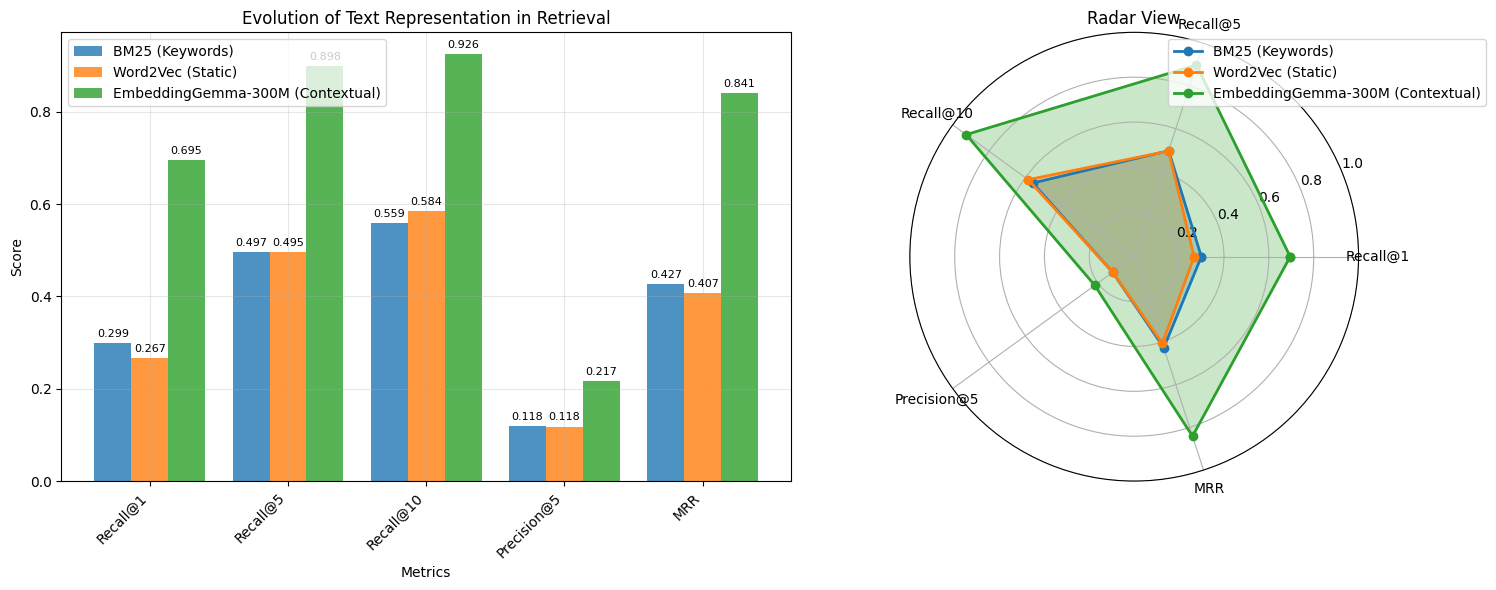

📈 Word2Vec: -4.7% MRR vs BM25
📈 EmbeddingGemma-300M: +97.2% MRR vs BM25


In [9]:
best_transformer = max(transformer_metrics_dict, key=lambda n: transformer_metrics_dict[n]['MRR'], default=None)

era_metrics = {'BM25 (Keywords)': bm25_metrics, 'Word2Vec (Static)': word2vec_metrics}
if best_transformer:
    era_metrics[f'{best_transformer} (Contextual)'] = transformer_metrics_dict[best_transformer]
else:
    print("⚠️  No transformer model loaded - comparing BM25 and Word2Vec only")
print_comparison_table(era_metrics, title="Keywords vs Static vs Contextual Embeddings")
create_comparison_visualization(
    era_metrics,
    title="Evolution of Text Representation in Retrieval",
    figsize=(16, 6), show_values=True, show_radar=True
)

for name in filter(None, ['Word2Vec', best_transformer]):
    gain = (all_metrics[name]['MRR'] - bm25_metrics['MRR']) / bm25_metrics['MRR'] * 100
    print(f"📈 {name}: {gain:+.1f}% MRR vs BM25")

## Transformer Model Comparison: 2021 vs 2023 vs 2025 Embedders

📊 Transformer Retrievers
Recall@1    : MiniLM-L6-v2=0.5603 | MPNet-base=0.6256 | BGE-small-v1.5=0.5972 | Qwen3-Embedding-0.6B=0.6093 | EmbeddingGemma-300M=0.6952
Recall@5    : MiniLM-L6-v2=0.7926 | MPNet-base=0.8538 | BGE-small-v1.5=0.8230 | Qwen3-Embedding-0.6B=0.8405 | EmbeddingGemma-300M=0.8983
Recall@10   : MiniLM-L6-v2=0.8484 | MPNet-base=0.8906 | BGE-small-v1.5=0.8664 | Qwen3-Embedding-0.6B=0.8807 | EmbeddingGemma-300M=0.9257
Precision@5 : MiniLM-L6-v2=0.1906 | MPNet-base=0.2059 | BGE-small-v1.5=0.1979 | Qwen3-Embedding-0.6B=0.2024 | EmbeddingGemma-300M=0.2173
MRR         : MiniLM-L6-v2=0.7188 | MPNet-base=0.7806 | BGE-small-v1.5=0.7507 | Qwen3-Embedding-0.6B=0.7670 | EmbeddingGemma-300M=0.8413


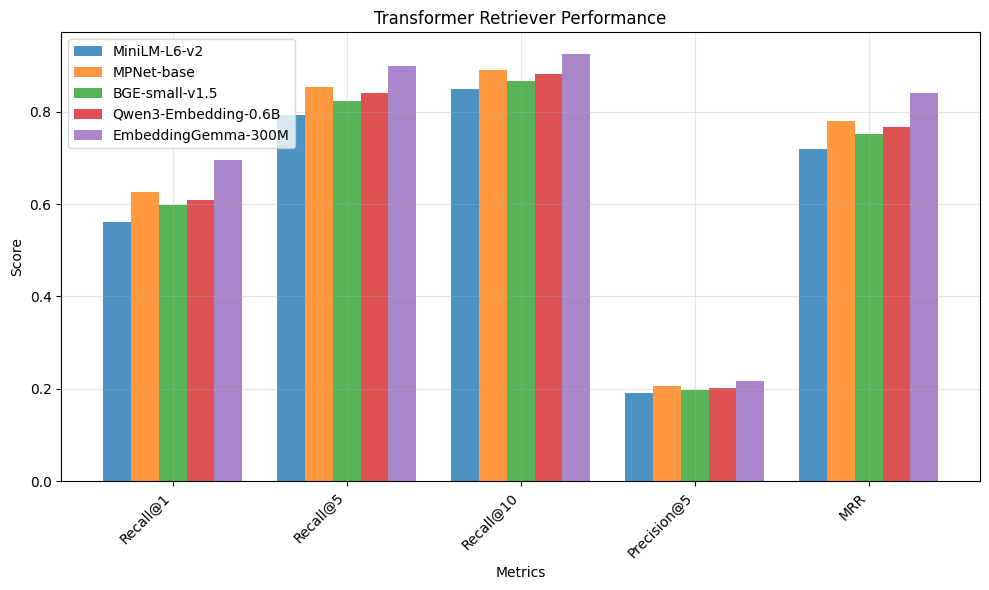

Model                      MRR  Recall@5   Dim  Index (s)  Queries (s)
EmbeddingGemma-300M     0.8413    0.8983   768       1723         14.4
MPNet-base              0.7806    0.8538   768       1142          9.9
Qwen3-Embedding-0.6B    0.7670    0.8405  1024       1765         20.1
BGE-small-v1.5          0.7507    0.8230   384        333          5.8
MiniLM-L6-v2            0.7188    0.7926   384        171          4.8


In [10]:
if not transformer_metrics_dict:
    raise SystemExit("No transformer model loaded - see the errors above")

print_comparison_table(transformer_metrics_dict, title="Transformer Retrievers")
create_comparison_visualization(
    transformer_metrics_dict,
    title="Transformer Retriever Performance",
    figsize=(16, 6), show_values=False, show_radar=False
)

print(f"{'Model':<22}{'MRR':>8}{'Recall@5':>10}{'Dim':>6}{'Index (s)':>11}{'Queries (s)':>13}")
for name in sorted(transformer_metrics_dict, key=lambda n: -transformer_metrics_dict[n]['MRR']):
    m, s = transformer_metrics_dict[name], model_stats[name]
    print(f"{name:<22}{m['MRR']:>8.4f}{m['Recall@5']:>10.4f}{s['embedding_dim']:>6}"
          f"{s['index_time_s']:>11.0f}{s['query_time_s']:>13.1f}")

## Hybrid Search: BM25 + Dense (Reciprocal Rank Fusion)

Keyword and dense retrievers fail on different questions: BM25 is strong on exact names, numbers and rare terms, while transformers handle paraphrases. **Reciprocal Rank Fusion** combines the two rankings using ranks only, which avoids calibrating BM25 scores against cosine similarities:

$$\text{score}(d) = \sum_{r \in \{\text{BM25},\ \text{dense}\}} \frac{1}{60 + \text{rank}_r(d)}$$

The hybrid fuses BM25 with the strongest transformer, using the standard constant 60 and no tuning on these questions.

In [11]:
hybrid_name = f"Hybrid (BM25 + {best_transformer})"
hybrid_retriever = HybridRetriever([bm25_retriever, retrievers[best_transformer]], depth=TOP_K)

# Fuse the rankings already computed above (no re-retrieval needed)
hybrid_results = HybridRetriever.fuse([bm25_results, all_results[best_transformer]], k=TOP_K)
hybrid_metrics = IRMetrics.evaluate_retrieval(hybrid_results, qrels_dict)
retrievers[hybrid_name], all_results[hybrid_name], all_metrics[hybrid_name] = hybrid_retriever, hybrid_results, hybrid_metrics

print_comparison_table({'BM25': bm25_metrics, best_transformer: all_metrics[best_transformer], hybrid_name: hybrid_metrics},
                       title="Hybrid vs Its Components")
print(f"Change vs {best_transformer} alone:")
for metric in ['Recall@1', 'Recall@5', 'Recall@10', 'MRR']:
    print(f"   {metric:<10} {hybrid_metrics[metric] - all_metrics[best_transformer][metric]:+.4f}")

📊 Hybrid vs Its Components
Recall@1    : BM25=0.2992 | EmbeddingGemma-300M=0.6952 | Hybrid (BM25 + EmbeddingGemma-300M)=0.4366
Recall@5    : BM25=0.4967 | EmbeddingGemma-300M=0.8983 | Hybrid (BM25 + EmbeddingGemma-300M)=0.8039
Recall@10   : BM25=0.5586 | EmbeddingGemma-300M=0.9257 | Hybrid (BM25 + EmbeddingGemma-300M)=0.9048
Precision@5 : BM25=0.1185 | EmbeddingGemma-300M=0.2173 | Hybrid (BM25 + EmbeddingGemma-300M)=0.1911
MRR         : BM25=0.4266 | EmbeddingGemma-300M=0.8413 | Hybrid (BM25 + EmbeddingGemma-300M)=0.6416
Change vs EmbeddingGemma-300M alone:
   Recall@1   -0.2586
   Recall@5   -0.0945
   Recall@10  -0.0209
   MRR        -0.1997


## Example Analysis

Side-by-side top results for a few random questions (✓ = relevant passage).

In [12]:
compare_retrieval_methods(
    query_texts=query_texts,
    corpus_texts=corpus_texts,
    qrels_dict=qrels_dict,
    results_dict={name: all_results[name] for name in filter(None, ['BM25', 'Word2Vec', best_transformer])},
    n_examples=5,
    top_k=3,
    seed=SEED
);

Retrieval Method Comparison

Example 1: 'how did orchestra change in the romantic period'
Ground Truth: 1 relevant document(s)

Relevant Documents:
   1. In the Romantic period, music became more expressive and emotional, expanding to encompass literary, artistic, and philo...

BM25 (Top 3):
   1. ✓ In the Romantic period, music became more expressive and emotional, expanding to encompass literary, artistic, and philo...
   2. ✗ The period typically called Romantic varies greatly between different countries and different artistic media or areas of...
   3. ✗ Biographer Peter Ames Carlin said of the track: "It's like the orchestra is falling apart. It's about the guy's wife, an...

Word2Vec (Top 3):
   1. ✓ In the Romantic period, music became more expressive and emotional, expanding to encompass literary, artistic, and philo...
   2. ✗ The period typically called Romantic varies greatly between different countries and different artistic media or areas of...
   3. ✗ The primacy of the c

## Key Insights

**BM25 (keywords)** is strong when the question and passage share rare terms such as names, titles and dates. That's common in NQ, so BM25 is a hard baseline to beat. It fails on paraphrases ("who wrote" vs "author of").

**Word2Vec (static embeddings)** captures word similarity, but averaging context-free vectors blurs a passage's meaning. Trained only on this corpus, it typically lands near or below BM25, which is why the field moved to large pre-trained models.

**Transformers (contextual embeddings)** encode meaning in context and are pre-trained on large datasets of question–passage pairs, so they find answers phrased differently from the question. The comparison above also shows the effect of the training objective: retrieval-tuned and recent LLM-based embedders (BGE, Qwen3, EmbeddingGemma) versus general-purpose sentence encoders, along with the cost in model size and indexing time.

## End-to-End Open-Domain QA: Retriever + Reader

Retrieval returns passages, not answers. To answer questions, the **best retriever from the benchmark above** (chosen by MRR) passes its top-5 passages to an **extractive reader**, `deepset/roberta-base-squad2`. This RoBERTa model, fine-tuned on SQuAD 2.0, picks the most likely answer span in each passage, and the highest-scoring span is returned.

**How it's measured:** BEIR's NQ release includes relevance judgments but **no answer strings**, so exact-match/F1 can't be computed. Two proxies are reported instead:
- **Retrieval hit rate**: a relevant passage is among the 5 the reader sees (the upper bound for the reader)
- **Gold-source rate**: the reader's answer comes from a relevant passage

In [13]:
best_name = max(all_metrics, key=lambda n: all_metrics[n]['MRR'])
best_retriever = retrievers[best_name]
print(f"🏆 Best retriever: {best_name} (MRR {all_metrics[best_name]['MRR']:.4f})")

# Free GPU memory held by transformer models the best retriever doesn't use
keep = {best_name, best_transformer} if best_name == hybrid_name else {best_name}
for name in transformer_metrics_dict:
    if name not in keep:
        retrievers[name].model = None
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

reader = ExtractiveReader("deepset/roberta-base-squad2")

eval_ids = random.Random(SEED).sample(sorted(qrels_dict), min(QA_EVAL_QUERIES, len(qrels_dict)))
qa_eval = reader.evaluate(query_texts, all_results[best_name], corpus_texts, qrels_dict,
                          query_ids=eval_ids, k=5)

print(f"\n📊 End-to-end QA on {len(eval_ids)} questions ({best_name} top-5 → RoBERTa reader)")
print(f"  Retrieval hit rate (relevant passage in top 5): {qa_eval['retrieval_hit_rate']:.1%}")
print(f"  Gold-source rate (answer from relevant passage): {qa_eval['gold_source_rate']:.1%}")

🏆 Best retriever: EmbeddingGemma-300M (MRR 0.8413)
📖 Loading reader model: deepset/roberta-base-squad2


config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Reader loaded: deepset/roberta-base-squad2 (cuda)


Reading: 100%|██████████| 500/500 [00:44<00:00, 11.14it/s]


📊 End-to-end QA on 500 questions (EmbeddingGemma-300M top-5 → RoBERTa reader)
  Retrieval hit rate (relevant passage in top 5): 92.2%
  Gold-source rate (answer from relevant passage): 45.8%


In [14]:
for p in qa_eval['predictions'][:10]:
    source = "✅ relevant passage" if p['from_relevant'] else "❌ non-relevant passage"
    print(f"❓ {p['question']}")
    print(f"💬 {p['answer']}   (confidence {p['score']:.2f}, retrieved rank {p['rank'] + 1}, {source})")
    print(f"   📄 {p['context'][:180]}...\n")

❓ how did orchestra change in the romantic period
💬 Beethoven would improvise at the piano   (confidence 0.18, retrieved rank 5, ❌ non-relevant passage)
   📄 Although Classical music in the 2000s has lost most of its tradition for musical improvisation, from the Baroque era to the Romantic era, there are examples of performers who could...

❓ who wrote hallelujah i just love her so
💬 Ray Charles   (confidence 0.96, retrieved rank 1, ✅ relevant passage)
   📄 "Hallelujah I Love Her So" is a single from American musician Ray Charles. The jazz and rhythm and blues song was written and released by Charles in 1956 on the Atlantic label, and...

❓ where does the big sur begin and end
💬 Anderson Creek   (confidence 0.24, retrieved rank 4, ❌ non-relevant passage)
   📄 Overcoming all the difficulties, the crews completed two portions of the highway in October, 1924, one section 12 miles (19 km) long from San Simeon to Salmon Creek and a second st...

❓ when did the flash first appear on arrow
💬 

### Ask Your Own Question
Searches the full benchmark corpus with the best retriever, then reads the top passages.

In [15]:
def ask(question, k=5):
    doc_ids = best_retriever.retrieve([question], k=k)[0]
    result = reader.answer(question, [corpus_texts[d] for d in doc_ids], doc_ids)
    print(f"❓ {question}\n💬 {result['answer']}  (confidence {result['score']:.2f})")
    print(f"📄 {result['context'][:300]}...")
    return result

# Replace with any question; this one is taken from the benchmark
ask(query_texts[eval_ids[-1]]);

🔍 Running semantic retrieval for 1 queries...
✅ Retrieved top-5 documents using semantic similarity
❓ the first element on the periodic table is
💬 hydrogen  (confidence 0.70)
📄 As of 2016[update], the periodic table has 118 confirmed elements, from element 1 (hydrogen) to 118 (oganesson). Elements 113, 115, 117 and 118, the most recent discoveries, were officially confirmed by the International Union of Pure and Applied Chemistry (IUPAC) in December 2015. Their proposed na...


## How This Fits a RAG Pipeline

Retrieval-Augmented Generation (RAG) answers questions in two stages:

**Question → Retriever → relevant passages → Generator / Reader → grounded answer**

The **retriever** selects the passages most likely to contain the answer from a large collection. The **generator** then answers using only that context. Here the generator is an extractive reader; in systems like **Perplexity**, **ChatGPT search** or **GitHub Copilot**'s codebase search, an LLM writes the answer from the retrieved context. Grounding the model in retrieved text lets it use current or private information and makes answers traceable to sources.

The reader can only answer from what it is given, so **retrieval quality caps end-to-end quality**. That's why this project spends most of its effort on comparing retrievers: moving from BM25 to modern transformer embedders directly raises the share of questions where the answer is even available to the reader.

## Results Summary

In [16]:
rows = sorted(all_metrics.items(), key=lambda kv: -kv[1]['MRR'])
table = ["| Retriever | Recall@1 | Recall@5 | Recall@10 | Precision@5 | MRR |", "|---|---|---|---|---|---|"]
for name, m in rows:
    label = f"**{name}**" if name == best_name else name
    table.append(f"| {label} | {m['Recall@1']:.3f} | {m['Recall@5']:.3f} | {m['Recall@10']:.3f} | {m['Precision@5']:.3f} | {m['MRR']:.3f} |")

display(Markdown(
    f"**Corpus:** {len(corpus_texts):,} passages · **Questions:** {len(query_texts):,}\n\n" + "\n".join(table) +
    f"\n\n**End-to-end QA** ({best_name} + RoBERTa reader, {len(eval_ids)} questions): "
    f"retrieval hit rate {qa_eval['retrieval_hit_rate']:.1%}, gold-source rate {qa_eval['gold_source_rate']:.1%}"
))

if skipped_models:
    print("⚠️  Skipped models: " + "; ".join(f"{n} ({err[:120]})" for n, err in skipped_models.items()))

os.makedirs(OUTPUT_DIR, exist_ok=True)
with open(os.path.join(OUTPUT_DIR, "metrics.json"), "w") as f:
    json.dump({
        'corpus_size': len(corpus_texts), 'num_questions': len(query_texts),
        'retrieval': all_metrics, 'transformer_stats': model_stats, 'best_retriever': best_name,
        'hybrid': hybrid_name, 'skipped_models': skipped_models,
        'qa': {k: v for k, v in qa_eval.items() if k != 'predictions'} | {'num_questions': len(eval_ids)}
    }, f, indent=2, default=float)
print(f"💾 Saved metrics to {OUTPUT_DIR}/metrics.json")

**Corpus:** 104,201 passages · **Questions:** 3,452

| Retriever | Recall@1 | Recall@5 | Recall@10 | Precision@5 | MRR |
|---|---|---|---|---|---|
| **EmbeddingGemma-300M** | 0.695 | 0.898 | 0.926 | 0.217 | 0.841 |
| MPNet-base | 0.626 | 0.854 | 0.891 | 0.206 | 0.781 |
| Qwen3-Embedding-0.6B | 0.609 | 0.840 | 0.881 | 0.202 | 0.767 |
| BGE-small-v1.5 | 0.597 | 0.823 | 0.866 | 0.198 | 0.751 |
| MiniLM-L6-v2 | 0.560 | 0.793 | 0.848 | 0.191 | 0.719 |
| Hybrid (BM25 + EmbeddingGemma-300M) | 0.437 | 0.804 | 0.905 | 0.191 | 0.642 |
| BM25 | 0.299 | 0.497 | 0.559 | 0.118 | 0.427 |
| Word2Vec | 0.267 | 0.495 | 0.584 | 0.118 | 0.407 |

**End-to-end QA** (EmbeddingGemma-300M + RoBERTa reader, 500 questions): retrieval hit rate 92.2%, gold-source rate 45.8%

💾 Saved metrics to /kaggle/working/metrics.json


## Conclusions and Next Steps

- Transformer dense retrieval clearly beats keyword and static-embedding retrieval on real questions; the results summary above shows by how much, and how model age, size and training data compare.
- Hybrid fusion shows whether exact keyword matching still adds anything on top of the strongest dense retriever.
- Retrieval quality is the ceiling for end-to-end QA: the reader can only answer from passages it receives.

**Possible extensions**
- **Re-ranking:** score the top-20 with a cross-encoder (e.g. `BAAI/bge-reranker-base`) for higher precision at rank 1
- **Approximate nearest-neighbor index** (FAISS) to scale to the full 2.68M-passage corpus
- **Generative reader:** replace the extractive reader with an instruction-tuned LLM for full RAG, evaluated with answer-level metrics on the original NQ answers